# 12 · Which industries hire IT staff

Which sectors post IT jobs: banks, manufacturers, telecoms, retailers or software firms?

**Method.** The feed's industry tags differ by board (Vietnamese on CareerBuilder, English on LinkedIn and CareerViet), so `taxonomy.sectors_of` groups them into about ten sectors by keyword; a posting can belong to several. Because the taxonomies and the boards differ, the two windows (**2021–22**, CareerBuilder, and **2025–26**, mostly LinkedIn and CareerViet) are shown **separately and never joined into one trend**. Shares are of postings that carry industry tags.

In [1]:
from vnjobs.analysis import core as a
from vnjobs.analysis import industries as ind

a.apply_style()
con = a.connect()
df = a.load_features(con)

## 1. Coverage

Share of postings with industry tags, per window and source.

In [2]:
coverage = ind.coverage(df)
a.save_table(coverage, "12-industry-coverage")
coverage

,window,source,postings,pct_with_industry
0,2021-22,CareerBuilder,20424,100.0
1,2021-22,Monster Asia,1331,92.6
2,2025-26,CareerBuilder,5963,99.7
3,2025-26,CareerJet,3633,0.0
4,2025-26,CareerViet,5281,100.0
5,2025-26,DEjobs,653,0.0
6,2025-26,Foundit,482,11.6
7,2025-26,Jora,13745,0.0
8,2025-26,LinkedIn,32913,95.5
9,2025-26,Manatal,456,0.0


## 2. The sectors, window by window

% of tagged postings in each sector (a posting can sit in several sectors, so the shares add to more than 100).

In [3]:
early = ind.sector_shares(df, ind.WINDOWS["2021-22"])
late = ind.sector_shares(df, ind.WINDOWS["2025-26"])
a.save_table(early, "12-sectors-2021-22")
a.save_table(late, "12-sectors-2025-26")
early.merge(late, on="sector", how="outer", suffixes=("_2021_22", "_2025_26")).sort_values(
    "share_2025_26", ascending=False
)

,sector,postings_2021_22,share_2021_22,postings_2025_26,share_2025_26
4,IT services & software,14556,67.2,25880,58.3
6,Manufacturing & electronics,4628,21.4,9293,20.9
8,Other,1574,7.3,5508,12.4
0,Banking & finance,2466,11.4,4127,9.3
2,"Energy, construction & property",1072,4.9,1654,3.7
9,Retail & e-commerce,463,2.1,1643,3.7
7,"Media, games & ads",445,2.1,1592,3.6
10,Telecom,1088,5.0,1057,2.4
3,Healthcare & pharma,353,1.6,878,2.0
5,Logistics & transport,61,0.3,570,1.3


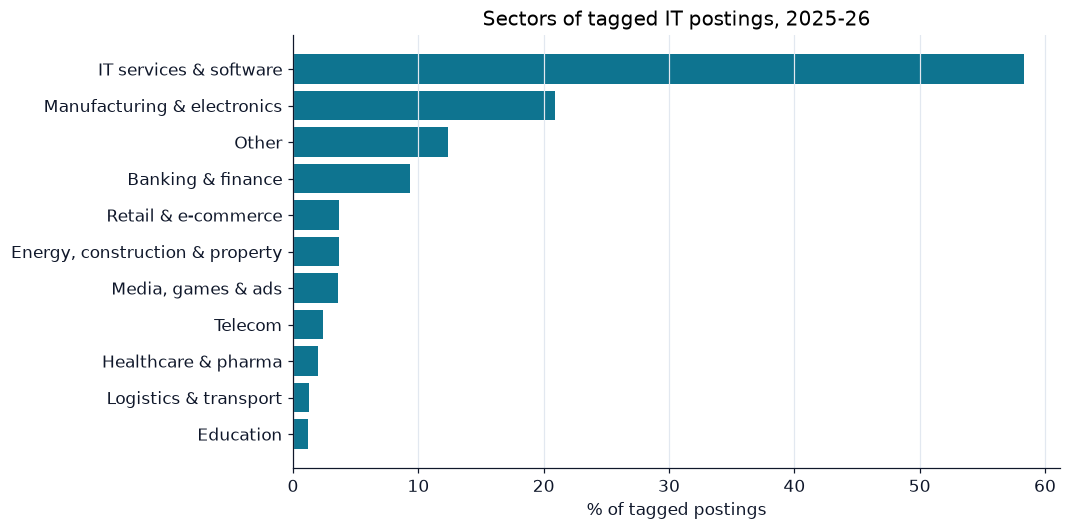

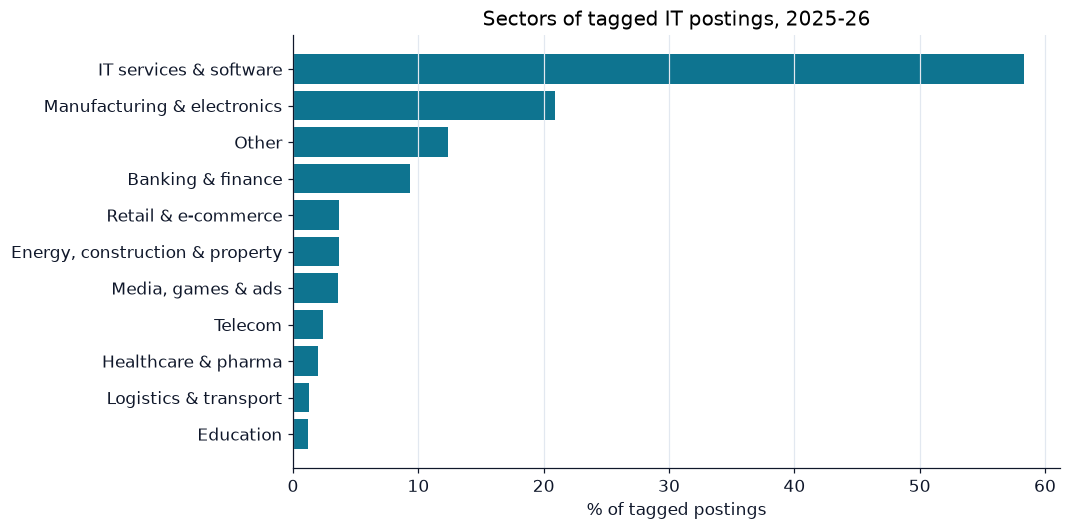

In [4]:
fig = a.barh(
    late, "sector", "share", "Sectors of tagged IT postings, 2025-26", "% of tagged postings"
)
a.save_chart(fig, "12-sectors-2025-26")
fig

## 3. Sector by role (2025-26)

For each role, the share of its tagged postings that sit in each sector.

In [5]:
by_role = ind.sector_by_role(df)
a.save_table(by_role, "12-sector-by-role")
by_role

,role,postings,Banking & finance,Education,"Energy, construction & property",Healthcare & pharma,IT services & software,Logistics & transport,Manufacturing & electronics,"Media, games & ads",Other,Retail & e-commerce,Telecom
0,backend,4469,10.6,1.0,0.6,1.3,76.1,1.0,4.1,4.2,9.9,3.3,1.6
1,fullstack,2273,5.1,1.0,2.0,1.2,75.0,2.5,4.2,4.1,12.1,2.6,0.4
2,data,4721,20.6,1.2,1.5,2.0,58.2,2.2,8.8,4.8,14.1,8.7,1.1
3,ai_ml,4542,14.1,1.9,1.1,0.9,66.3,1.1,8.7,5.1,12.0,3.7,1.7
4,devops_cloud,3337,11.8,0.8,6.2,1.0,67.3,1.8,9.6,3.7,10.1,2.4,3.3
5,qa_test,5839,4.5,0.9,4.7,4.9,49.8,0.7,23.7,2.9,15.6,3.5,1.5
6,security,1438,18.4,1.3,1.5,0.3,64.6,0.6,16.6,2.9,15.9,5.4,3.8


## 4. Where juniors are hired (2025-26)

Entry-level share of known-level postings, per sector.

In [6]:
entry = ind.entry_by_sector(df)
a.save_table(entry, "12-entry-by-sector")
entry

,sector,known_level_postings,entry
0,Education,505,47.9
1,Other,5234,41.9
2,Retail & e-commerce,1484,40.2
3,Telecom,924,38.9
4,Manufacturing & electronics,8346,36.2
5,Healthcare & pharma,797,35.8
6,IT services & software,24919,32.9
7,"Energy, construction & property",1529,29.1
8,Banking & finance,4003,23.7
9,"Media, games & ads",1543,23.6


## Findings

1. **IT hiring sits mostly inside IT companies, with manufacturing and banks next.** Of postings with industry tags, IT services and software are 58 % in 2025–26 (67 % in 2021–22), manufacturing and electronics about 21 % in both windows, banking and finance 9.3 % (11.4 %), telecom 2.4 % (5.0 %), retail and e-commerce 3.7 % (2.1 %), media, games and ads 3.6 % (2.1 %), energy, construction and property 3.7 % (4.9 %), healthcare 2.0 % (1.6 %). The two windows come from different boards and taxonomies, so read them as an ordering, not a precise trend.
2. **Roles differ by sector.** Banking holds 20.6 % of data postings and 18.4 % of security postings, against 10.6 % of backend and 5.1 % of full-stack. Manufacturing and electronics holds 23.7 % of QA postings against 4.1 % of backend.
3. **Banks are among the hardest places for a junior to get in.** Entry-level share of known-level postings by sector (2025–26): education 47.9 %, retail 40.2 %, telecom 38.9 %, manufacturing 36.2 %, IT services 32.9 %, banking 23.7 %, media and games 23.6 %, logistics 21.1 %.
4. **Coverage and caveats.** Industry tags are on 95–100 % of LinkedIn, CareerViet and CareerBuilder postings and on none of Jora, CareerJet and DEjobs, so those sources are left out. "Other" is 7–12 %. Part of the manufacturing share is the same technician and electrical-engineering jobs found in `03-roles`.

**What this notebook cannot say:** the sector of the employer for the untagged sources, or how the sector mix moved between the two windows beyond the ordering.
